   order_id customer_id customer_name  age  gender       city        state  \
0      1001        C001  Aarav Sharma   28    Male     Mumbai  Maharashtra   
1      1002        C002   Priya Patel   35  Female      Delhi        Delhi   
2      1003        C003   Rahul Verma   22    Male  Bangalore    Karnataka   
3      1004        C004   Sneha Reddy   30  Female  Hyderabad    Telangana   
4      1005        C005  Vikram Singh   45    Male    Chennai   Tamil Nadu   
5      1006        C006   Ananya Nair   27  Female       Pune  Maharashtra   
6      1007        C007   Arjun Mehta   33    Male    Kolkata  West Bengal   
7      1008        C008    Deepa Iyer   40  Female     Jaipur    Rajasthan   

         category        product_name  quantity  unit_price  total_price  \
0     Electronics          Smartphone         1       25000        25000   
1        Clothing               Saree         2        3500         7000   
2     Electronics              Laptop         1       55000        55

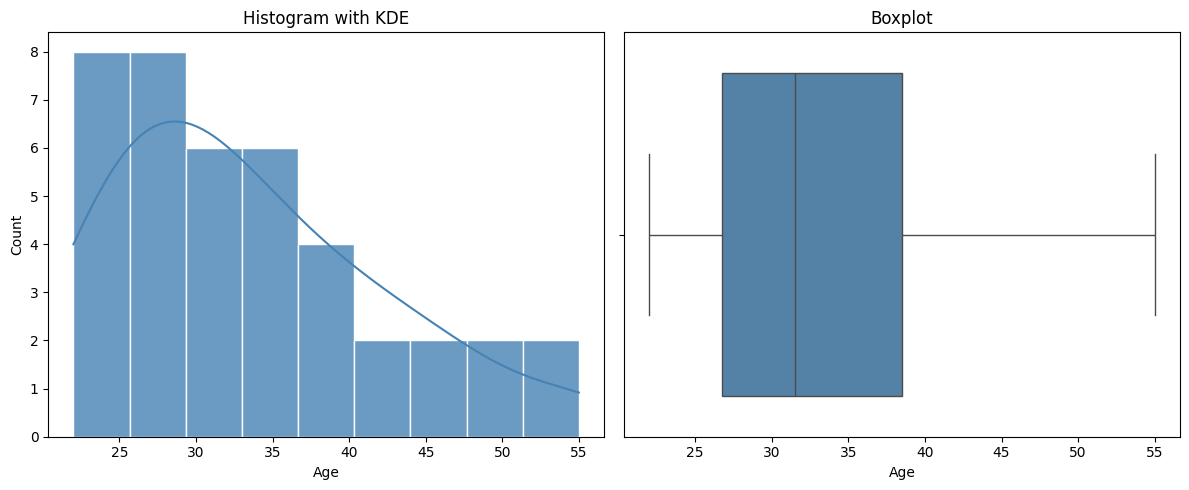

Most common age group. 20-30


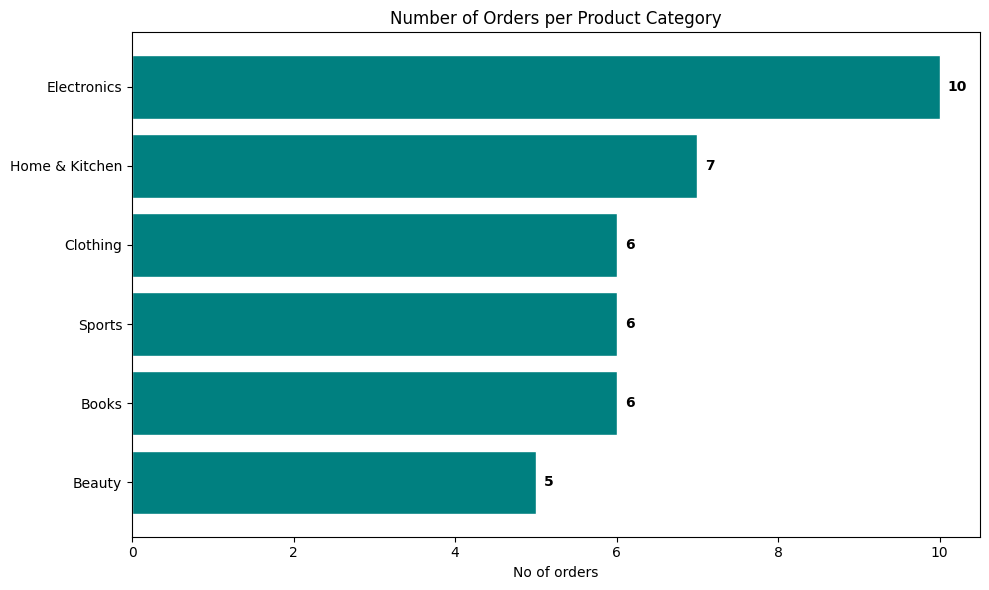

Category with most orderd. Electronics


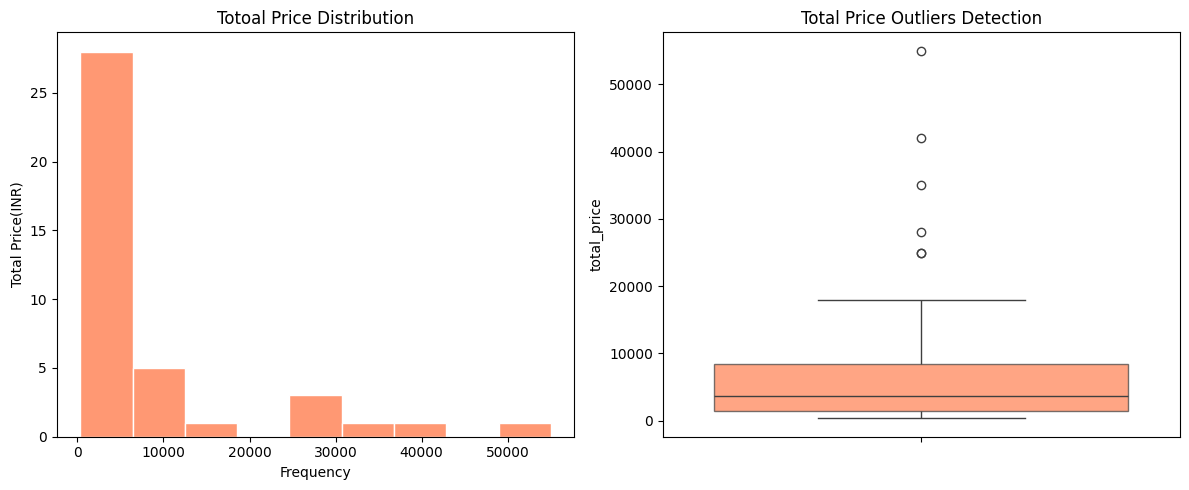

Skewness: 2.2687421039069093
Kurtosis: 4.93700746161181


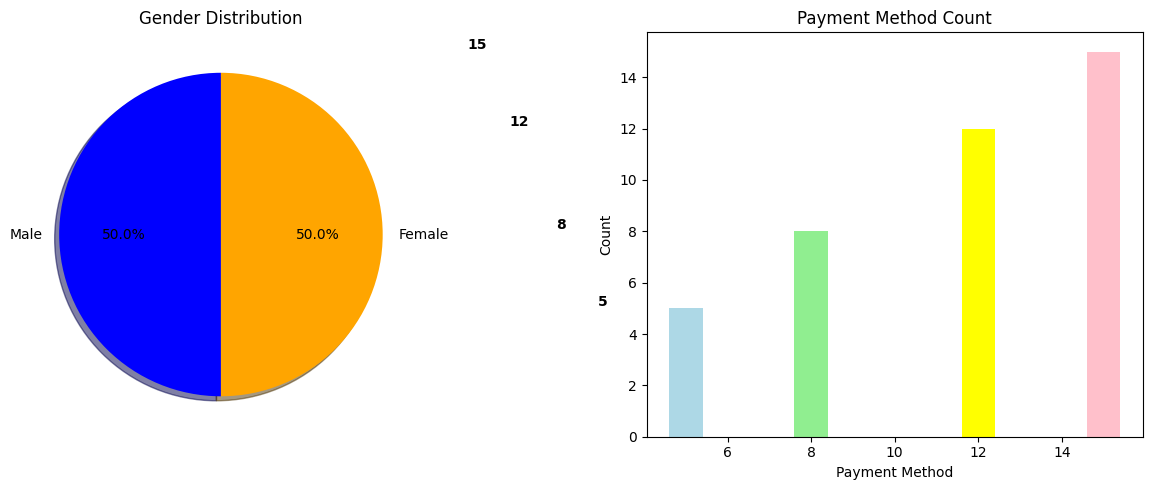

Most popular payment menthod: Credit Card


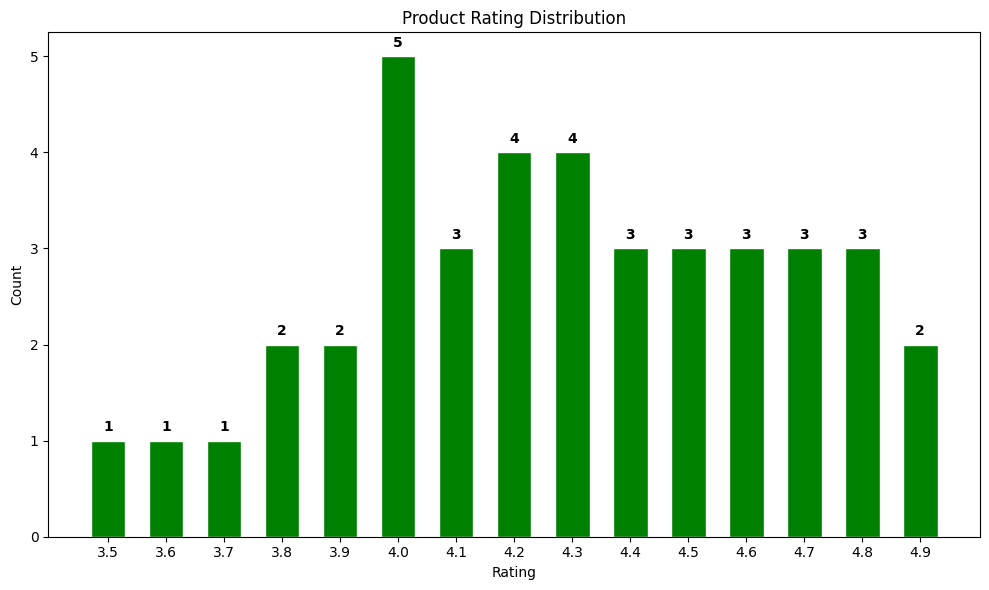

Mean rating:4.28
Products with rating>4.5:11


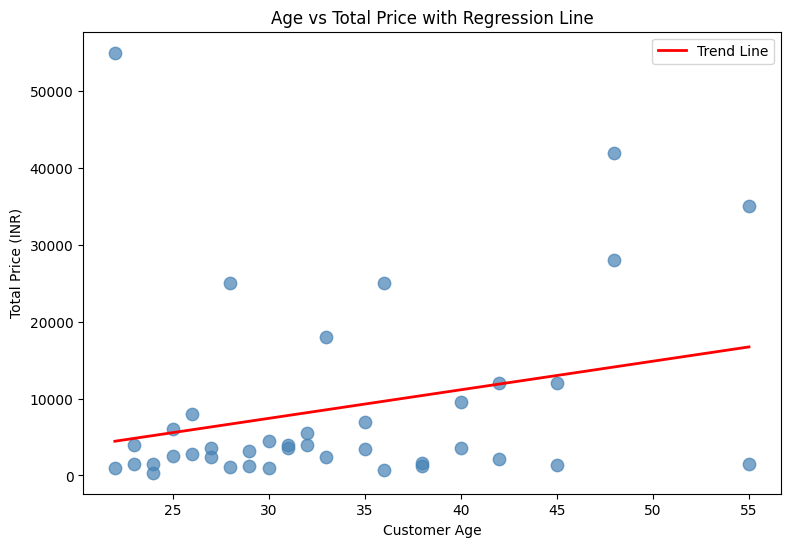

Pearson Correlation (Age vs Total Price): 0.2634


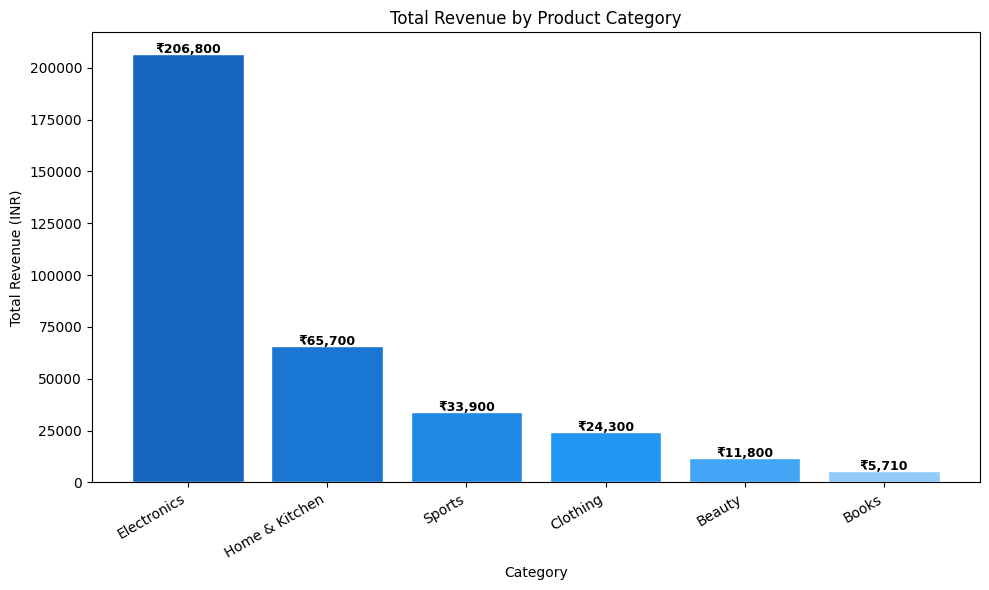

Highest revenue: Electronics - 206800
Lowest revenue: Books - 5710


In [ ]:
#Project for ecommerce sales

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url="https://raw.githubusercontent.com/suresh-79-90/DataSets/main/ecommerce_sales.csv"
df=pd.read_csv(url)
# Display first 8 rows print('=== First 8 Rows ===')
print(df.head(8))
# Display last 5 rows
print('\n=== Last 5 Rows ===')
print(df.tail(5))

# (a) Shape of dataset
print('Shape:', df.shape)
#(b) Column names and data types
print('\nColumn Names and Data Types:')
print(df.dtypes)
# (c) Non-null value counts
print('\nNon-null value counts:')
print(df.info())

#Summary statistics for numerical columns
num_cols=df.select_dtypes(include=np.number).columns.tolist()
stats = df[num_cols].describe()

#Add median row
stats.loc['median'] = df[num_cols].median()
print(stats.round(2))

#Missing value count
missing_count=df.isnull().sum()
missing_pct=(df.isnull().sum()/len(df)*100).round(2)
# print(missing_count)
# print(missing_pct)

missing_df=pd.DataFrame({
    'Missing Count':missing_count,
    'Missing %':missing_pct
})

print(missing_df[missing_df['Missing Count']>0])

if missing_count.sum()==0:
  print('\nNo missing values')
else:
  print('\nMissing values')

#check and remove duplicate rows
print('Shape before deduplication:',df.shape)

#Check for duplicates
duplicate=df.duplicated()
print('Number of duplicate rows:',df.duplicated().sum())

if duplicate.sum()>0:
  print(df[duplicate])
  df=df.drop_duplicates().reset_index(drop=True)
  print('Shape after deduplication:',df.shape)
else:
  print('No duplicates')


#Age distribution - histogram with KDE and boxplot

fig,axes=plt.subplots(1,2,figsize=(12,5))

#Histogram with KDE
sns.histplot(df['age'],bins=9,color='steelblue',edgecolor='white',alpha=0.8,
              ax=axes[0],kde=True)
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Count')
axes[0].set_title('Histogram with KDE')

#Boxplot
sns.boxplot(x=df['age'],ax=axes[1],color='steelblue')
axes[1].set_xlabel('Age')
axes[1].set_title('Boxplot')

plt.tight_layout()
plt.show()

age_bins=pd.cut(df['age'],bins=[20,30,40,50,60],labels=['20-30','30-40','40-50','50-60'])
# df['age_bins']=age_bins
print('Most common age group.',age_bins.value_counts().idxmax())

#ST-7: Category value counts and horizontal bar chart
cat_counts=df['category'].value_counts().sort_values(ascending=True)

plt.figure(figsize=(10,6))
bars=plt.barh(cat_counts.index,cat_counts.values,color='teal',edgecolor='white')
plt.xlabel('No of orders')
# plt.ylabel('Number of Orders per Product Category')
plt.title('Number of Orders per Product Category')

for bar, val in zip(bars,cat_counts.values):
    plt.text(
        bar.get_width()+0.1,
        bar.get_y()+bar.get_height()/2,
         str(val),
        va='center',
        fontweight='bold')
plt.tight_layout()
plt.savefig('category_orders.png',dpi=150)
plt.show()

print('Category with most orderd.',df['category'].value_counts().idxmax())

#ST-8 Total price distribution-skewness analysis
fig,axes=plt.subplots(1,2,figsize=(12,5))

#Histogram
sns.histplot(df['total_price'],bins=9,color='coral',edgecolor='white',alpha=0.8,
              ax=axes[0])
axes[0].set_xlabel('Frequency')
axes[0].set_ylabel('Total Price(INR)')
axes[0].set_title('Totoal Price Distribution')

#Boxplot
sns.boxplot(df['total_price'],patch_artist=True,
            boxprops=dict(facecolor='coral',alpha=0.7),ax=axes[1])
#axes[1].set_xlabel('Total Price(INR)')
axes[1].set_title('Total Price Outliers Detection')
plt.tight_layout()
plt.savefig('total_price_distribution.png',dpi=150)
plt.show()

from scipy import stats
skew_val=df['total_price'].skew()
kurt_val=df['total_price'].kurt()
print('Skewness:',skew_val)
print('Kurtosis:',kurt_val)

#St-9 Gender pie chart and payment method count plot
fig,axes=plt.subplots(1,2,figsize=(12,5))

gender_counts = df['gender'].value_counts()
axes[0].pie(gender_counts,labels=gender_counts.index,
        autopct='%1.1f%%',
        colors=['blue','orange'],startangle=90,shadow=True)
axes[0].set_title('Gender Distribution')

payment_counts = df['payment_method'].value_counts()
axes[1].bar(payment_counts,payment_counts.values,
            color=['pink','yellow','lightgreen','lightblue'])
axes[1].set_xlabel('Payment Method')
axes[1].set_ylabel('Count')
axes[1].set_title('Payment Method Count')
# axes[1].legend(loc='upper right')
# plt.show()

for i,v in enumerate(df['payment_method'].value_counts().values):
  axes[1].text(i,v+0.1,str(v),ha='center',fontweight='bold')

plt.tight_layout()
plt.savefig('gender_payment.png',dpi=150)
plt.show()

print('Most popular payment menthod:',df['payment_method'].value_counts().idxmax())

#St-10 Product rating distibution analysis

plt.figure(figsize=(10,6))
rating_counts=df['rating'].value_counts().sort_index()
plt.bar(rating_counts.index.astype(str),rating_counts.values,color='green',edgecolor='white',width=0.6)
plt.xlabel('Rating')
plt.ylabel('Count')
plt.title('Product Rating Distribution')

for i,(r,v) in enumerate(zip(rating_counts.index,
                            rating_counts.values)):
  plt.text(i,v+0.1,str(v),ha='center',fontweight='bold')
plt.tight_layout()
plt.savefig('product_rating.png',dpi=150)
plt.show()

mean_rating=df['rating'].mean()
high_rated=(df['rating']>4.5).sum()
print(f'Mean rating:{mean_rating:.2f}')
print(f'Products with rating>4.5:{high_rated}')

# STEP-11. Age vs Total Price scatter plot + correlation
plt.figure(figsize=(9, 6))
plt.scatter(df['age'], df['total_price'], color='steelblue', alpha=0.7, s=80)

# Regression line
m, b = np.polyfit(df['age'], df['total_price'], 1)
x_line = np.linspace(df['age'].min(), df['age'].max(), 100)
plt.plot(x_line, m * x_line + b, color='red', linewidth=2, label=f'Trend Line')

plt.xlabel('Customer Age')
plt.ylabel('Total Price (INR)')
plt.title('Age vs Total Price with Regression Line')
plt.legend()
plt.savefig('age_vs_price.png', dpi=150)
plt.show()

corr = df['age'].corr(df['total_price'])
print(f'Pearson Correlation (Age vs Total Price): {corr:.4f}')

# STEP-12. Total sales by category — grouped bar chart
category_revenue = df.groupby('category')['total_price'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
colors = ['#1565C0','#1976D2','#1E88E5','#2196F3','#42A5F5','#90CAF9']
bars = plt.bar(category_revenue.index, category_revenue.values, color=colors, edgecolor='white')

for bar, val in zip(bars, category_revenue.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
             f'₹{val:,.0f}', ha='center', fontsize=9, fontweight='bold')

plt.xlabel('Category')
plt.ylabel('Total Revenue (INR)')
plt.title('Total Revenue by Product Category')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('category_revenue.png', dpi=150)
plt.show()

print('Highest revenue:', category_revenue.idxmax(), '-', category_revenue.max())
print('Lowest revenue:', category_revenue.idxmin(), '-', category_revenue.min())


